In [99]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.datasets import cifar10

In [100]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Training labels:", y_train.shape)

Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Training labels: (50000, 1)


In [92]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

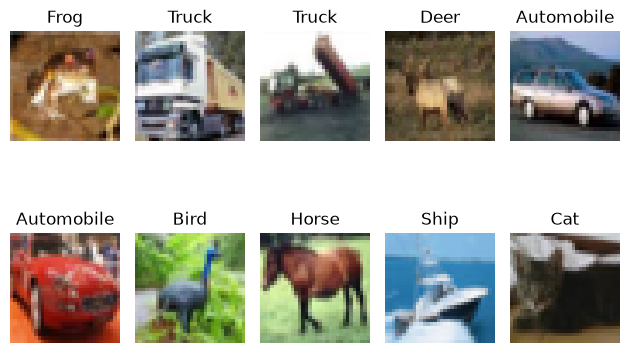

In [113]:
for i in range(10):
    plt.subplot(2,5, i+1)
    plt.imshow(x_train[i])
    plt.axis('off')
    plt.title(class_names[y_train[i][0]])

plt.tight_layout()
plt.show()

In [114]:
x_train = x_train/255.0
x_test = x_test/255.0

In [116]:
model = Sequential()
model.add(Input(shape=(32,32,3)))
model.add(Flatten())
model.add(Dense(512, kernel_initializer='uniform', activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(256, kernel_initializer='uniform', activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(128, kernel_initializer='uniform', activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [117]:
model.fit(x_train, y_train, batch_size=64, epochs=20, validation_split=0.2)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.2440 - loss: 2.0286 - val_accuracy: 0.3194 - val_loss: 1.8852
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.3128 - loss: 1.8921 - val_accuracy: 0.3544 - val_loss: 1.8075
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.3357 - loss: 1.8348 - val_accuracy: 0.3764 - val_loss: 1.7454
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.3514 - loss: 1.8002 - val_accuracy: 0.3787 - val_loss: 1.7269
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.3589 - loss: 1.7733 - val_accuracy: 0.3890 - val_loss: 1.7219
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.3674 - loss: 1.7501 - val_accuracy: 0.4010 - val_loss: 1.6844
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - accuracy: 0.3764 - loss: 1.7306 - val_accuracy: 0.3992 - val_loss: 1.6743
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.3825 - loss: 1.7189 - 

In [118]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4359 - loss: 1.5645
Test Loss: 1.5645252466201782
Test Accuracy: 0.4359000027179718


In [119]:
y_pred_test = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


In [126]:
class_names[y_test[2][0]]

'Ship'

In [127]:
class_names[np.argmax(y_pred_test[2])]

'Ship'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


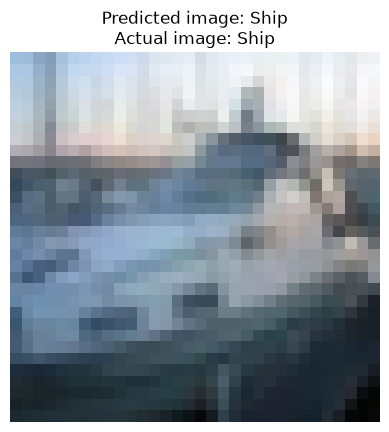

In [139]:
image = x_test[2]

prediction = model.predict(
    np.expand_dims(image, axis=0)
)

predicted_class = np.argmax(prediction)
actual_class = y_test[2][0]

plt.imshow(image)
plt.title(
    f"Predicted image: {class_names[predicted_class]}\n"
    f"Actual image: {class_names[actual_class]}"
)
plt.axis('off')
plt.show()

In [151]:
model.save('cifar10_pred.h5')

In [152]:
from tensorflow.keras.models import load_model

cifar10_pred = load_model('cifar10_pred.h5')

In [169]:
def cifar10_prediction(image):
    image = image.resize((32, 32))
    image = image.convert('RGB')
    image = np.array(image, dtype=np.float32)

    image = image/255.0

    image = np.expand_dims(image, axis=0)

    predicted = cifar10_pred(image)

    predicted_class = np.argmax(predicted)

    return class_names[predicted_class]

In [172]:
from PIL import Image

img_path = r'E:\jupyter\DL\Chapter-7 (Image Classification Scripting)\Task-1 (CIFAR10 Dataset classification prediction)\Screenshot1.png'

image = Image.open(img_path)

In [173]:
cifar10_prediction(image)

'Horse'